In [3]:
# solar_system_3d.py

import matplotlib.pyplot as plt

class SolarSystem:
    def __init__(self, size):
        self.size = size
        self.bodies = []

        self.fig, self.ax = plt.subplots(
            1,
            1,
            subplot_kw={"projection": "3d"},
            figsize=(self.size / 50, self.size / 50),
        )
        self.fig.tight_layout()

    def add_body(self, body):
        self.bodies.append(body)
    

In [ ]:
# solar_system_3d.py

import numpy as np
from matplotlib.animation import FuncAnimation
import matplotlib
matplotlib.use("TkAgg")
import matplotlib.pyplot as plt


class SolarSystem:
    def __init__(
        self,
        size=20,
        num_agents=30,
        dt=0.02,
    ):

        self.size = size
        self.num_agents = num_agents
        self.dt = dt

        # -----------------------------
        # Physics Parameters
        # -----------------------------
        self.agent_radius = 0.3
        self.agent_mass = 1.0

        self.drag_coeff = 0.05
        self.air_density = 0.02

        self.restitution = 0.9

        # Lennard-Jones
        self.lj_epsilon = 10.0
        self.lj_sigma = 0.9

        # Milling
        self.milling_enabled = False
        self.milling_fov_angle = 120
        self.milling_speed = 3.0
        self.milling_turn_rate = 2.0

        # -----------------------------
        # State Variables
        # -----------------------------
        self.pos = np.random.uniform(
            -size / 4,
            size / 4,
            (num_agents, 3),
        )

        self.vel = np.random.randn(num_agents, 3)
        self.acc = np.zeros((num_agents, 3))

        # -----------------------------
        # Matplotlib Setup
        # -----------------------------
        self.fig = plt.figure(figsize=(8, 8))
        self.ax = self.fig.add_subplot(111, projection="3d")

        self.ax.set_xlim(-size / 2, size / 2)
        self.ax.set_ylim(-size / 2, size / 2)
        self.ax.set_zlim(-size / 2, size / 2)

        self.scatter = self.ax.scatter(
            self.pos[:, 0],
            self.pos[:, 1],
            self.pos[:, 2],
            s=40,
        )

    # =====================================================
    # Main Physics Step
    # =====================================================

    def step(self):

        dt = self.dt
        n = self.num_agents
        mass = self.agent_mass

        self.acc[:] = 0

        # =================================================
        # DRAG
        # =================================================

        speeds = np.linalg.norm(self.vel, axis=1, keepdims=True)

        moving = speeds.flatten() > 1e-5

        if np.any(moving):

            drag_mag = (
                0.5
                * self.air_density
                * speeds[moving] ** 2
                * self.drag_coeff
            )

            drag_force = (
                -(self.vel[moving] / speeds[moving])
                * drag_mag
            )

            self.acc[moving] += drag_force / mass

        # =================================================
        # LENNARD-JONES SWARM FORCES
        # =================================================

        diff = (
            self.pos[:, np.newaxis, :]
            - self.pos[np.newaxis, :, :]
        )

        dist = np.linalg.norm(diff, axis=-1)

        np.fill_diagonal(dist, np.inf)

        sigma = self.lj_sigma
        epsilon = self.lj_epsilon

        sr6 = (sigma / dist) ** 6
        sr12 = sr6 ** 2

        force_mag = (
            24
            * epsilon
            * (2 * sr12 - sr6)
            / dist
        )

        # Clamp force
        max_force = 50.0

        force_mag = np.clip(
            force_mag,
            -max_force,
            max_force,
        )

        direction = diff / dist[..., np.newaxis]

        lj_force = np.sum(
            force_mag[..., np.newaxis] * direction,
            axis=1,
        )

        self.acc += lj_force / mass

        # =================================================
        # MILLING BEHAVIOR
        # =================================================

        if self.milling_enabled:

            headings = np.where(
                speeds > 1e-5,
                self.vel / np.maximum(speeds, 1e-5),
                np.random.randn(n, 3),
            )

            headings /= np.linalg.norm(
                headings,
                axis=1,
                keepdims=True,
            )

            z_axis = np.array([0.0, 0.0, 1.0])

            lateral = np.cross(z_axis, headings)

            lateral_norm = np.linalg.norm(
                lateral,
                axis=1,
                keepdims=True,
            )

            valid = lateral_norm.flatten() > 1e-5

            lateral[valid] /= lateral_norm[valid]

            turn_accel = (
                self.milling_speed
                * self.milling_turn_rate
                * lateral
            )

            self.acc += turn_accel

            # Maintain forward speed
            speed_error = (
                self.milling_speed
                - speeds.flatten()
            )

            forward = (
                headings
                * speed_error[:, np.newaxis]
            )

            self.acc += forward

        # =================================================
        # INTEGRATE
        # =================================================

        self.vel += self.acc * dt

        # Speed clamp
        max_speed = 10.0

        speeds = np.linalg.norm(
            self.vel,
            axis=1,
            keepdims=True,
        )

        too_fast = speeds.flatten() > max_speed

        if np.any(too_fast):

            self.vel[too_fast] *= (
                max_speed / speeds[too_fast]
            )

        self.pos += self.vel * dt

        # =================================================
        # WALL COLLISIONS
        # =================================================

        limit = self.size / 2

        for i in range(3):

            pos_wall = self.pos[:, i] > limit

            self.pos[pos_wall, i] = limit
            self.vel[pos_wall, i] *= -self.restitution

            neg_wall = self.pos[:, i] < -limit

            self.pos[neg_wall, i] = -limit
            self.vel[neg_wall, i] *= -self.restitution

    # =====================================================
    # ANIMATION UPDATE
    # =====================================================

    def update(self, frame):

        self.step()

        self.scatter._offsets3d = (
            self.pos[:, 0],
            self.pos[:, 1],
            self.pos[:, 2],
        )

        return self.scatter,

    # =====================================================
    # RUN SIMULATION
    # =====================================================

    def run(self):

       self.anim = FuncAnimation(
        self.fig,
        self.update,
        interval=20,
        blit=False,
        cache_frame_data=False,
    ) 

    plt.show()



# =========================================================
# MAIN
# =========================================================

if __name__ == "__main__":

    sim = SolarSystem(
        size=20,
        num_agents=5,
    )

    sim.run()

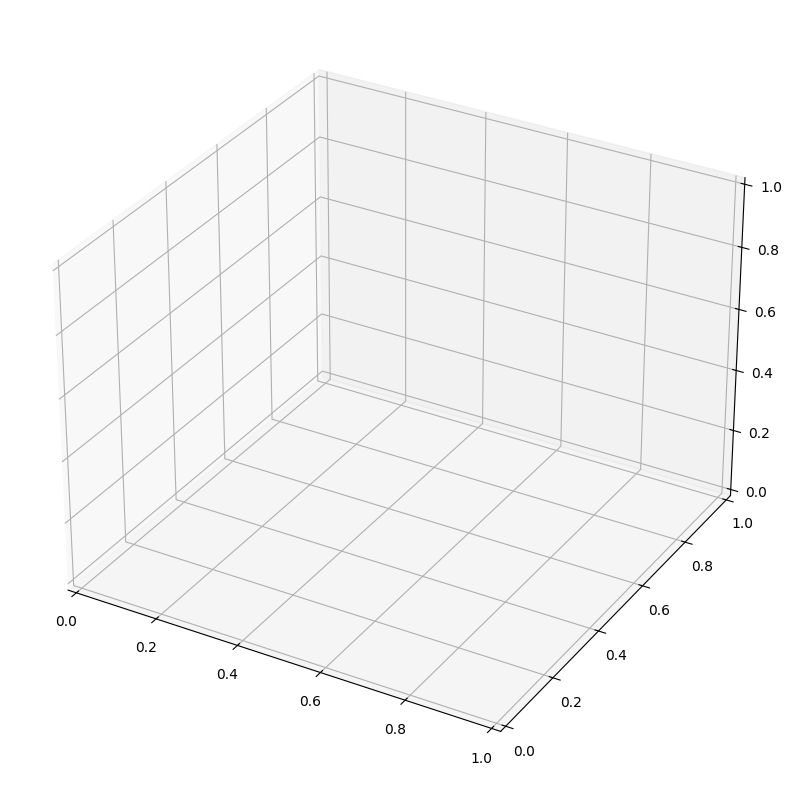

In [4]:

SolarSystem(400)
plt.show()  # if not using interactive mode

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

# ============================================
# LOAD CSV
# ============================================

df = pd.read_csv("simulation_data_1778645000.csv")

# ============================================
# SETTINGS
# ============================================

num_agents = 10

# ============================================
# COMPUTE AVERAGE INTER-AGENT DISTANCE
# ============================================

average_distances = []

for _, row in df.iterrows():

    # ----------------------------------------
    # Collect positions for all agents
    # ----------------------------------------

    positions = []

    for i in range(num_agents):

        x = row[f"Agent{i}_X"]
        y = row[f"Agent{i}_Y"]
        z = row[f"Agent{i}_Z"]

        positions.append([x, y, z])

    positions = np.array(positions)

    # ----------------------------------------
    # Compute pairwise distances
    # ----------------------------------------

    distances = []

    for i, j in combinations(range(num_agents), 2):

        d = np.linalg.norm(
            positions[i] - positions[j]
        )

        distances.append(d)

    # ----------------------------------------
    # Average distance
    # ----------------------------------------

    avg_distance = np.mean(distances)

    average_distances.append(avg_distance)

# ============================================
# SAVE RESULTS
# ============================================

df["Average_Distance"] = average_distances

df.to_csv(
    "average_interagent_distance.csv",
    index=False
)

# ============================================
# PLOT
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["Time"],
    df["Average_Distance"],
)

plt.xlabel("Time")
plt.ylabel("Average Inter-Agent Distance")
plt.title("Swarm Cohesion Over Time")

plt.grid(True)

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'simulation_data_1778645000.csv'